# Laboratorium 5: Ekstrakcja informacji -- reguły, NER i LLM

W tym laboratorium porównujemy trzy sposoby rozpoznawania nazw własnych (encji nazwanych, ang. named entity recognition, NER) w tekstach polskich:

`reguły → model NER → LLM z odpowiedzią w formacie JSON`

Wszystkie systemy działają na tym samym zbiorze referencyjnym i zwracają wyniki w tym samym formacie:

```json
{"text": "Olga Tokarczuk", "label": "PER", "start": 0, "end": 14}
```

Przyjmujemy konwencję `text[start:end]`: `start` jest indeksem pierwszego znaku encji, a `end` -- indeksem pierwszego znaku po niej (indeks wyłączny).

Główne pytanie laboratorium brzmi:

**Kiedy wystarczą reguły, kiedy lepszy jest model NER, a kiedy warto użyć LLM?**

## Po tych zajęciach student potrafi

- przygotować i skontrolować zbiór referencyjny oraz podzielić go na część rozwojową (DEV) i testową (TEST);
- zaimplementować ewaluację ścisłego i częściowego dopasowania zakresów;
- rozróżnić błąd klasy encji od błędu jej granic;
- zbudować prosty system regułowy;
- wykorzystać słownik nazw (`gazetteer`) w systemie regułowym i uwzględnić w nim fleksję języka polskiego;
- uruchomić i ocenić wstępnie wytrenowany model NER;
- sprawdzić wpływ progu pewności na precision i recall;
- uzyskać od LLM odpowiedź w formacie JSON i kontrolować jej poprawność;
- porównać jakość, szybkość i typy błędów trzech podejść;
- uzasadnić wybór rozwiązania dla konkretnego zastosowania.

## Ustawienia wstępne

Wymagane biblioteki:

```bash
pip install pandas numpy matplotlib transformers torch requests scikit-learn
```

**Model NER (język polski):**

```text
pczarnik/herbert-base-ner
```

To model HerBERT (`allegro/herbert-base-cased`) dostrojony do rozpoznawania nazw własnych na polskiej części zbioru WikiANN. Rozpoznaje klasy `PER`, `ORG` i `LOC`; etykiety mają postać IOB2 (`B-PER`, `I-PER` itd.). Pierwsze uruchomienie pobiera ok. 0,5 GB.

**Model językowy (LLM):** lokalnie przez [Ollamę](https://ollama.com). Model musi dobrze radzić sobie z językiem polskim. Propozycja:

```bash
ollama run hf.co/speakleash/Bielik-4.5B-v3.0-Instruct-GGUF:Q8_0
```

(polski model Bielik, ok. 5 GB, licencja Apache 2.0). Można użyć innego modelu wskazanego na zajęciach; w karcie systemu należy podać jego nazwę, kwantyzację i ustawienia generowania (`temperature`).

**Zasady oceny.** Wszystkie podejścia porównujemy na tym samym zbiorze referencyjnym. Zbiór dzielimy na część rozwojową (DEV) i testową (TEST):

- reguły, słownik i prompt tworzymy i poprawiamy **wyłącznie na DEV**;
- wszystkie tabele z wynikami liczymy **na TEST**, chyba że w poleceniu napisano inaczej;
- nie oceniamy systemów na podstawie pojedynczych przykładów.

In [1]:
from pathlib import Path
import json
import re
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import requests
from transformers import pipeline, AutoModelForTokenClassification, AutoTokenizer

ARTIFACTS = Path("../artifacts")
ARTIFACTS.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 220)

W1106 10:44:16.923000 14433 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Zbiór referencyjny

Poniższy zbiór zawiera 30 polskich zdań z ręcznie oznaczonymi encjami:

- `PER`: osoba;
- `ORG`: organizacja;
- `LOC`: lokalizacja.

Ten sam zbiór będzie używany do oceny wszystkich trzech podejść. Dzielimy go na część rozwojową (DEV, 10 dokumentów) i testową (TEST, 20 dokumentów); podział jest zdefiniowany w komórce poniżej i nie wolno go zmieniać.

In [2]:
RAW = [
("Donald Tusk spotkał się w Warszawie z przedstawicielami Komisji Europejskiej.",
 [("Donald Tusk","PER"),("Warszawie","LOC"),("Komisji Europejskiej","ORG")]),
("Olga Tokarczuk odebrała nagrodę podczas wydarzenia organizowanego przez Uniwersytet Wrocławski.",
 [("Olga Tokarczuk","PER"),("Uniwersytet Wrocławski","ORG")]),
("Robert Lewandowski przyleciał do Krakowa na spotkanie z przedstawicielami PZPN.",
 [("Robert Lewandowski","PER"),("Krakowa","LOC"),("PZPN","ORG")]),
("Microsoft otworzył nowe biuro w Warszawie, a Satya Nadella zapowiedział dalsze inwestycje.",
 [("Microsoft","ORG"),("Warszawie","LOC"),("Satya Nadella","PER")]),
("AGH w Krakowie podpisała umowę z firmą IBM.",
 [("AGH","ORG"),("Krakowie","LOC"),("IBM","ORG")]),
("Andrzej Sapkowski spotkał się z czytelnikami w Łodzi.",
 [("Andrzej Sapkowski","PER"),("Łodzi","LOC")]),
("Ministerstwo Finansów opublikowało raport przygotowany wspólnie z Narodowym Bankiem Polskim.",
 [("Ministerstwo Finansów","ORG"),("Narodowym Bankiem Polskim","ORG")]),
("Maria Nowak z firmy Allegro przeprowadziła prezentację w Poznaniu.",
 [("Maria Nowak","PER"),("Allegro","ORG"),("Poznaniu","LOC")]),
("Google zaprosił Jana Kowalskiego do swojego biura w Londynie.",
 [("Google","ORG"),("Jana Kowalskiego","PER"),("Londynie","LOC")]),
("Muzeum Narodowe w Krakowie otworzyło wystawę poświęconą Stanisławowi Wyspiańskiemu.",
 [("Muzeum Narodowe w Krakowie","ORG"),("Stanisławowi Wyspiańskiemu","PER")]),
("Joanna Bator była gościem Uniwersytetu Jagiellońskiego.",
 [("Joanna Bator","PER"),("Uniwersytetu Jagiellońskiego","ORG")]),
("Amazon rozwija centrum logistyczne pod Wrocławiem.",
 [("Amazon","ORG"),("Wrocławiem","LOC")]),
("Prezydent Warszawy Rafał Trzaskowski odwiedził Pragę.",
 [("Warszawy","LOC"),("Rafał Trzaskowski","PER"),("Pragę","LOC")]),
("Naukowcy z Politechniki Gdańskiej współpracują z zespołem z Uniwersytetu Stanforda.",
 [("Politechniki Gdańskiej","ORG"),("Uniwersytetu Stanforda","ORG")]),
("Anna Dymna prowadzi fundację Mimo Wszystko w Krakowie.",
 [("Anna Dymna","PER"),("Mimo Wszystko","ORG"),("Krakowie","LOC")]),
("Spotify zatrudnił Piotra Zielińskiego w swoim oddziale w Sztokholmie.",
 [("Spotify","ORG"),("Piotra Zielińskiego","PER"),("Sztokholmie","LOC")]),
("Bank Pekao współpracuje z Uniwersytetem Ekonomicznym w Katowicach.",
 [("Bank Pekao","ORG"),("Uniwersytetem Ekonomicznym w Katowicach","ORG")]),
("Marta Lempart uczestniczyła w konferencji zorganizowanej w Berlinie.",
 [("Marta Lempart","PER"),("Berlinie","LOC")]),
("Firma CD Projekt zaprosiła Adama Badowskiego na wydarzenie w Los Angeles.",
 [("CD Projekt","ORG"),("Adama Badowskiego","PER"),("Los Angeles","LOC")]),
("Europejska Agencja Kosmiczna współpracuje z NASA przy projekcie realizowanym w Paryżu.",
 [("Europejska Agencja Kosmiczna","ORG"),("NASA","ORG"),("Paryżu","LOC")]),
("Wisława Szymborska przez wiele lat mieszkała w Krakowie.",
 [("Wisława Szymborska","PER"),("Krakowie","LOC")]),
("Orange Polska otworzył punkt badawczy na Politechnice Warszawskiej.",
 [("Orange Polska","ORG"),("Politechnice Warszawskiej","ORG")]),
("Adam Małysz odwiedził Zakopane podczas wydarzenia organizowanego przez TVP Sport.",
 [("Adam Małysz","PER"),("Zakopane","LOC"),("TVP Sport","ORG")]),
("PKP Intercity uruchomiło nowe połączenie między Warszawą a Pragą.",
 [("PKP Intercity","ORG"),("Warszawą","LOC"),("Pragą","LOC")]),
("Michał Rusinek wystąpił na Uniwersytecie Śląskim w Katowicach.",
 [("Michał Rusinek","PER"),("Uniwersytecie Śląskim w Katowicach","ORG")]),
("Samsung zorganizował konferencję w Seulu, na której wystąpił Lee Jae-yong.",
 [("Samsung","ORG"),("Seulu","LOC"),("Lee Jae-yong","PER")]),
("Fundacja Batorego zaprosiła Anne Applebaum na debatę w Warszawie.",
 [("Fundacja Batorego","ORG"),("Anne Applebaum","PER"),("Warszawie","LOC")]),
("Grupa Azoty podpisała porozumienie z Akademią Górniczo-Hutniczą.",
 [("Grupa Azoty","ORG"),("Akademią Górniczo-Hutniczą","ORG")]),
("Iga Świątek wróciła z Paryża po turnieju organizowanym przez Francuską Federację Tenisową.",
 [("Iga Świątek","PER"),("Paryża","LOC"),("Francuską Federację Tenisową","ORG")]),
("Zespół OpenAI spotkał się z badaczami z MIT w Bostonie.",
 [("OpenAI","ORG"),("MIT","ORG"),("Bostonie","LOC")]),
]

def build_gold(raw):
    docs=[]
    for i,(text, ents) in enumerate(raw):
        out=[]
        used=0
        for entity,label in ents:
            start=text.find(entity, used)
            if start < 0:
                start=text.find(entity)
            if start < 0:
                raise ValueError((entity,text))
            end=start+len(entity)
            out.append({"text":entity,"label":label,"start":start,"end":end})
            used=end
        docs.append({"doc_id":i,"text":text,"entities":out})
    return docs

GOLD = build_gold(RAW)

# Podział zbioru: DEV (do budowy reguł, słownika i promptu); TEST (do oceny).

DEV  = [d for d in GOLD if d["doc_id"] % 3 == 0]
TEST = [d for d in GOLD if d["doc_id"] % 3 != 0]

print("dokumenty (razem / DEV / TEST):", len(GOLD), len(DEV), len(TEST))
print("encje (razem):", sum(len(d["entities"]) for d in GOLD))
print("encje w TEST:", Counter(e["label"] for d in TEST for e in d["entities"]))


dokumenty (razem / DEV / TEST): 30 10 20
encje (razem): 77
encje w TEST: Counter({'ORG': 22, 'LOC': 17, 'PER': 13})


In [3]:
print(DEV[0])

{'doc_id': 0, 'text': 'Donald Tusk spotkał się w Warszawie z przedstawicielami Komisji Europejskiej.', 'entities': [{'text': 'Donald Tusk', 'label': 'PER', 'start': 0, 'end': 11}, {'text': 'Warszawie', 'label': 'LOC', 'start': 26, 'end': 35}, {'text': 'Komisji Europejskiej', 'label': 'ORG', 'start': 56, 'end': 76}]}


# Zadanie 1: Audyt zbioru referencyjnego

Proszę zaimplementować kontrolę danych, która sprawdza:

1. czy `text[start:end]` jest identyczne z polem `text` encji;
2. czy `start < end`;
3. czy zakres mieści się w dokumencie;
4. czy etykieta należy do `{PER, ORG, LOC}`;
5. czy w jednym dokumencie nie występują zduplikowane adnotacje;
6. czy zakresy encji w jednym dokumencie nie nakładają się na siebie (przyjmujemy płaskie encje, bez zagnieżdżeń).

Następnie proszę podać:

- liczbę dokumentów;
- liczbę encji;
- rozkład klas (osobno dla DEV i TEST);
- średnią liczbę encji na dokument.

Na końcu proszę zapisać krótkie wytyczne adnotacji: co dokładnie uznajemy za `PER`, `ORG` i `LOC` oraz jak ustalamy granice encji. Wytyczne muszą rozstrzygać co najmniej trzy przypadki graniczne występujące w zbiorze, np.:

- czy dopełnienie lokalizacyjne należy do nazwy organizacji („Muzeum Narodowe w Krakowie” a „AGH w Krakowie”);
- czy stanowisko lub tytuł należy do encji `PER` („Prezydent Warszawy Rafał Trzaskowski”);
- czy nazwę miasta lub kraju wewnątrz nazwy instytucji oznaczamy dodatkowo jako `LOC`.

In [4]:
# Proszę zaimplementować audyt zbioru referencyjnego.

LABELS = {"PER", "ORG", "LOC"}

def validate_doc(doc):
    text, problems = doc["text"], []
    valid_spans = []

    for e in doc["entities"]:
        start, end = e["start"], e["end"]
        ok = True
        if not start < end:
            problems.append(("start >= end", e)); ok = False
        if not (0 <= start and end <= len(text)):
            problems.append(("poza dokumentem", e)); ok = False
        if ok and text[start:end] != e["text"]:
            problems.append(("tekst != text[start:end]", e)); ok = False
        if e["label"] not in LABELS:
            problems.append(("zła etykieta", e)); ok = False
        if ok:
            valid_spans.append(e)

    seen, unique = set(), []
    for e in valid_spans:
        key = (e["start"], e["end"], e["label"])
        if key in seen:
            problems.append(("duplikat", e))
        else:
            seen.add(key); unique.append(e)

    unique.sort(key=lambda e: (e["start"], e["end"]))
    for prev, cur in zip(unique, unique[1:]):
        if cur["start"] < prev["end"]:
            problems.append(("nakładanie", (prev, cur)))
    return problems


all_problems = [(d["doc_id"], p) for d in GOLD for p in validate_doc(d)]
print(f"Znalezione problemy: {len(all_problems)}")
for doc_id, p in all_problems:
    print(doc_id, p)



Znalezione problemy: 0


In [5]:
def stats(docs):
    n_ent =  sum(len(d["entities"]) for d in docs)
    c = Counter(e["label"] for d in docs for e in d["entities"])
    return {"dokumenty": len(docs), "encje": n_ent, "PER": c["PER"], "ORG": c["ORG"], "LOC": c["LOC"],
        "encje / dokument": round(n_ent / len(docs), 2)}

summary = pd.DataFrame({"DEV": stats(DEV), "TEST": stats(TEST), "razem": stats(GOLD)}).T
summary.astype({"dokumenty": int, "encje": int, "PER": int, "ORG": int, "LOC": int})

,dokumenty,encje,PER,ORG,LOC,encje / dokument
DEV,10,25,7,12,6,2.50
TEST,20,52,13,22,17,2.60
razem,30,77,20,34,23,2.57


### Wytyczne adnotacji

Zbiór referencyjny stosuje następujące zasady (rozstrzygają przypadki graniczne występujące w zdaniach):

- **Klasy.** `PER`: osoba (imię i nazwisko). `ORG`: organizacja, firma, instytucja, fundacja, uczelnia, także skrótowce (PZPN, NASA). `LOC`: lokalizacja (miasto, kraj).
- **Granice.** Oznaczamy tylko samą nazwę własną, w formie występującej w tekście (z odmianą, np. „Jana Kowalskiego”, „Warszawie”). Encje są płaskie, bez zagnieżdżeń.
- **Dopełnienie lokalizacyjne w nazwie organizacji.** Należy do `ORG`, jeśli jest częścią nazwy własnej: „Muzeum Narodowe w Krakowie”, „Uniwersytecie Śląskim w Katowicach”. Jeśli miasto tylko wskazuje położenie (nie jest częścią nazwy), jest osobną encją `LOC`: w „AGH w Krakowie” `AGH` to `ORG`, a „Krakowie” to `LOC`.
- **Stanowisko, tytuł i rzeczowniki pospolite przed nazwą** nie należą do encji. Z „Prezydent Warszawy Rafał Trzaskowski” oznaczamy „Rafał Trzaskowski” (`PER`) oraz „Warszawy” (`LOC`), z „firmą IBM” samo „IBM”, z „fundację Mimo Wszystko” samo „Mimo Wszystko”, z „Zespół OpenAI” samo „OpenAI”.
- **Nazwa miasta wewnątrz nazwy instytucji** nie jest dodatkowo oznaczana jako `LOC` (brak zagnieżdżeń): „Politechniki Gdańskiej”, „Uniwersytet Wrocławski” to wyłącznie `ORG`.

# Zadanie 2: Metryki zakresowe i błędy granic

Proszę zaimplementować dwie procedury ewaluacyjne.

## Ścisłe dopasowanie (`exact span match`)

Predykcja jest poprawna tylko wtedy, gdy zgadzają się:

- `start`;
- `end`;
- `label`.

## Częściowe dopasowanie (`relaxed span match`)

Predykcja może zostać uznana za trafioną, jeżeli:

- zakres predykcji nachodzi na zakres referencyjny;
- dopasowanie jest wzajemnie jednoznaczne (1:1): każda predykcja i każda encja referencyjna należy do najwyżej jednej pary. Jeśli kilka predykcji nachodzi na jedną encję, dopasowujemy tę o największej części wspólnej; pozostałe liczymy jako fałszywie dodatnie.

Dla obu wariantów proszę policzyć precision, recall i F1. Metryki liczymy zbiorczo (micro) po wszystkich dokumentach; jeśli mianownik jest równy zero, przyjmujemy wartość 0.0.

Dodatkowo proszę zaimplementować liczenie błędów granic (`boundary error`): to para dopasowana w trybie częściowym, ale nie w ścisłym -- etykieta jest poprawna, zakresy nachodzą na siebie, ale `start` lub `end` się różnią.

Proszę przygotować co najmniej pięć ręcznie zapisanych przypadków testowych sprawdzających poprawność implementacji. Powinny one obejmować m.in.: idealną zgodność, błąd granicy, poprawny zakres z błędną klasą, dwie predykcje nachodzące na jedną encję, jedną predykcję obejmującą dwie encje oraz pustą listę predykcji.

In [6]:
print(GOLD[1])

{'doc_id': 1, 'text': 'Olga Tokarczuk odebrała nagrodę podczas wydarzenia organizowanego przez Uniwersytet Wrocławski.', 'entities': [{'text': 'Olga Tokarczuk', 'label': 'PER', 'start': 0, 'end': 14}, {'text': 'Uniwersytet Wrocławski', 'label': 'ORG', 'start': 72, 'end': 94}]}


In [7]:
# Proszę zaimplementować:
# exact_span_metrics(...)
# relaxed_span_metrics(...)
# count_boundary_errors(...)


def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return {"tp": tp, "fp": fp, "fn": fn, "precision": p, "recall": r, "f1": f1}

def span_key(e):
    return e["start"], e["end"], e["label"]

def overlap(a, b):
    return max(0, min(a["end"], b["end"]) - max(a["start"], b["start"]))


def relaxed_matches(gold, pred):
    pairs = [(g, p) for g in gold for p in pred if g['label'] == p['label'] and overlap(g, p) > 0]

    pairs.sort(key=lambda gp: (-overlap(*gp), span_key(gp[0]) != span_key(gp[1])))
    used_g, used_p, matched = set(), set(), []
    for g, p in pairs:
        if id(g) not in used_g and id(p) not in used_p:
            used_g.add(id(g))
            used_p.add(id(p))
            matched.append((g, p))
    return matched

def exact_span_metrics(gold_docs, pred_docs):
    tp, fp, fn = 0, 0, 0
    for g_doc, p_doc in zip(gold_docs, pred_docs):
        g = Counter(span_key(e) for e in g_doc['entities'])
        p = Counter(span_key(e) for e in p_doc['entities'])
        hit = sum((g & p).values())
        tp += hit
        fp += sum(p.values()) - hit
        fn += sum(g.values()) - hit
    return prf(tp, fp, fn)


def relaxed_span_metrics(gold_docs, pred_docs):
    tp = fp = fn = 0
    for g_doc, p_doc in zip(gold_docs, pred_docs):
        hit = len(relaxed_matches(g_doc["entities"], p_doc["entities"]))
        tp += hit
        fp += len(p_doc["entities"]) - hit
        fn += len(g_doc["entities"]) - hit
    return prf(tp, fp, fn)

def count_boundary_errors(gold_docs, pred_docs):
    return sum(span_key(g) != span_key(p)
               for g_doc, p_doc in zip(gold_docs, pred_docs)
               for g, p in relaxed_matches(g_doc["entities"], p_doc["entities"]))


In [8]:
tests = [
    ("idealna zgodność",
     [{"entities": [{"start": 0, "end": 5, "label": "PER"}]}],
     [{"entities": [{"start": 0, "end": 5, "label": "PER"}]}],
     (1, 0, 0), (1, 0, 0), 0),
    ("błąd granicy",
     [{"entities": [{"start": 0, "end": 11, "label": "PER"}]}],
     [{"entities": [{"start": 0, "end": 5, "label": "PER"}]}],
     (0, 1, 1), (1, 0, 0), 1),
    ("dobry zakres, zła klasa",
     [{"entities": [{"start": 0, "end": 5, "label": "PER"}]}],
     [{"entities": [{"start": 0, "end": 5, "label": "ORG"}]}],
     (0, 1, 1), (0, 1, 1), 0),
    ("dwie predykcje na jedną",
     [{"entities": [{"start": 0, "end": 11, "label": "PER"}]}],
     [{"entities": [{"start": 0, "end": 5, "label": "PER"}, {"start": 6, "end": 11, "label": "PER"}]}],
     (0, 2, 1), (1, 1, 0), 1),
    ("jedna predykcja na dwie",
     [{"entities": [{"start": 0, "end": 5, "label": "ORG"}, {"start": 6, "end": 11, "label": "ORG"}]}],
     [{"entities": [{"start": 0, "end": 11, "label": "ORG"}]}],
     (0, 1, 2), (1, 0, 1), 1),
    ("pusta lista predykcji",
     [{"entities": [{"start": 0, "end": 5, "label": "PER"}]}],
     [{"entities": []}],
     (0, 0, 1), (0, 0, 1), 0),
]

for name, gold, pred, exact, relaxed, boundary in tests:
    e, r = exact_span_metrics(gold, pred), relaxed_span_metrics(gold, pred)
    assert (e["tp"], e["fp"], e["fn"]) == exact, (name, "exact", e)
    assert (r["tp"], r["fp"], r["fn"]) == relaxed, (name, "relaxed", r)
    assert count_boundary_errors(gold, pred) == boundary, (name, "boundary")
print(f"Wszystkie {len(tests)} testy przeszły")

Wszystkie 6 testy przeszły


# Zadanie 3: System regułowy

Proszę zbudować pierwszy system ekstrakcji bez modelu uczącego się.

System powinien korzystać co najmniej z:

- wyrażeń regularnych;
- reguł dotyczących wielkich liter i sąsiedztwa słów;
- słownika nazw (`gazetteer`) zawierającego wybrane organizacje i lokalizacje.

Reguły, słownik i wyrażenia regularne tworzymy na podstawie części DEV oraz wiedzy ogólnej (np. listy największych polskich miast ustalonej **przed** obejrzeniem TEST). Słownik nie może zawierać nazw przepisanych ze zdań TEST.

Wskazówki dotyczące języka polskiego:

- w wyrażeniach regularnych wielką literę należy opisać także dla znaków diakrytycznych, np. `[A-ZĄĆĘŁŃÓŚŹŻ][a-ząćęłńóśźż]+` (klasa `[A-Z]` ich nie obejmuje);
- język polski jest fleksyjny: nazwa ze słownika („Kraków”) pojawia się w tekście w różnych formach („w Krakowie”, „do Krakowa”). Proszę zaproponować i zaimplementować sposób dopasowania odmienionych form (np. dopasowanie rdzenia lub prefiksu albo lista form) oraz opisać jego ograniczenie.

Wynik musi mieć ten sam format co zbiór referencyjny.

Proszę zmierzyć:

- exact precision / recall / F1;
- relaxed precision / recall / F1;
- liczbę błędów granic;
- F1 osobno dla `PER`, `ORG`, `LOC`;
- średni czas przetwarzania dokumentu.

Wyniki proszę podać osobno dla DEV i TEST i skomentować różnicę (jej duża wartość to sygnał dopasowania reguł do DEV). Proszę też krótko wskazać (na podstawie DEV), które reguły i które elementy słownika dały największą poprawę względem najprostszej wersji systemu.

In [9]:
# Proszę zaimplementować system regułowy ze słownikiem encji.

TOKEN_RE = re.compile(r"\w+(?:-\w+)*")
CAP_RE = re.compile(r"[A-ZĄĆĘŁŃÓŚŹŻ]")
ENDINGS = frozenset({"", "a", "u", "y", "e", "i", "ie", "ę", "ą", "em", "iem", "ia", "iu", "ach", "ami", "om", "ów"})


LOC_GAZ = tuple((s,) for s in ("Warszaw", "Kraków", "Krakow", "Łódź", "Łodzi", "Wrocław", "Poznań", "Poznani",
                               "Gdańsk", "Szczecin", "Bydgoszcz", "Lublin", "Białystok", "Katowic", "Gdyn",
                               "Częstochow", "Radom", "Toruń", "Toruni", "Kielc", "Rzeszów", "Rzeszow", "Olsztyn",
                               "Prag", "Pradze", "Sztokholm")) + (("Los", "Angeles"),)
ORG_GAZ = (("Microsoft",), ("Spotify",), ("CD", "Projekt"), ("Orange", "Polsk"))
ORG_TRIGGERS = ("Ministerstw", "Muze", "Uniwersytet", "Uniwersytec", "Politechnik", "Politechnic", "Akademi",
                "Bank", "Komisj", "Grup", "Instytut", "Instytuc", "Szpital", "Sąd", "Urząd", "Urzęd", "Stowarzyszeni")
TITLES = frozenset({"Prezydent", "Premier", "Minister", "Profesor", "Doktor", "Pan", "Pani"})


def matches(token, stem):
    return token.startswith(stem) and token[len(stem):] in ENDINGS


def is_free_cap(words, label, i):
    return label[i] is None and CAP_RE.match(words[i]) is not None


def cap_runs(text, toks, words, label):
    i, n = 0, len(words)
    while i < n:
        if not is_free_cap(words, label, i):
            i += 1
            continue
        j = i
        while (j + 1 < n and is_free_cap(words, label, j + 1)
               and text[toks[j].end():toks[j + 1].start()].isspace()):
            j += 1
        yield i, j
        i = j + 1


def take(label, spans, i, j, lab):
    label[i:j + 1] = [lab] * (j - i + 1)
    spans.append((i, j, lab))


def extract_entities(text, loc_gaz=LOC_GAZ, org_gaz=ORG_GAZ, org_triggers=ORG_TRIGGERS, titles=TITLES):
    toks = list(TOKEN_RE.finditer(text))
    words = [t.group() for t in toks]
    n, label, spans = len(words), [None] * len(words), []
    org_triggers = tuple(org_triggers)

    for i, j in cap_runs(text, toks, words, label):
        if any(w.startswith(org_triggers) for w in words[i:j + 1]):
            if j + 2 < n and words[j + 1] == "w" and is_free_cap(words, label, j + 2):
                j += 2
            take(label, spans, i, j, "ORG")

    for lab, gaz in (("LOC", loc_gaz), ("ORG", org_gaz)):
        for stems in gaz:
            L = len(stems)
            for i in range(n - L + 1):
                if not any(label[i:i + L]) and all(matches(words[i + k], s) for k, s in enumerate(stems)):
                    take(label, spans, i, i + L - 1, lab)

    for i, j in cap_runs(text, toks, words, label):
        while i <= j and words[i] in titles:
            i += 1
        if 2 <= j - i + 1 <= 3:
            take(label, spans, i, j, "PER")

    return [{"text": text[toks[i].start():toks[j].end()], "label": lab,
             "start": toks[i].start(), "end": toks[j].end()} for i, j, lab in sorted(spans)]


def predict(docs, **kw):
    return [{"doc_id": d["doc_id"], "text": d["text"], "entities": extract_entities(d["text"], **kw)} for d in docs]


def only(docs, lab):
    return [{"entities": [e for e in d["entities"] if e["label"] == lab]} for d in docs]


def report(docs, name, predict_fn=predict, **kw):
    t = time.perf_counter()
    pred = predict_fn(docs, **kw)
    ms = (time.perf_counter() - t) / len(docs) * 1000
    ex, rx = exact_span_metrics(docs, pred), relaxed_span_metrics(docs, pred)
    return {"zbiór": name,
            "exact P": ex["precision"], "exact R": ex["recall"], "exact F1": ex["f1"],
            "relaxed P": rx["precision"], "relaxed R": rx["recall"], "relaxed F1": rx["f1"],
            "błędy granic": count_boundary_errors(docs, pred),
            **{f"F1 {lab}": exact_span_metrics(only(docs, lab), only(pred, lab))["f1"] for lab in ["PER", "ORG", "LOC"]},
            "ms/dok": ms}


def dev_f1(**kw):
    return exact_span_metrics(DEV, predict(DEV, **kw))["f1"]


results_df = pd.DataFrame([report(DEV, "DEV"), report(TEST, "TEST")]).set_index("zbiór")
display(results_df.round(3).T)


steps = {"tylko PER (ciągi wielkich liter)": dict(org_triggers=(), loc_gaz=(), org_gaz=()),
         "+ wyzwalacze ORG":                 dict(loc_gaz=(), org_gaz=()),
         "+ gazetteer LOC":                  dict(org_gaz=()),
         "+ gazetteer ORG (pełny system)":   dict()}
ablation_df = pd.DataFrame({name: report(DEV, name, **kw) for name, kw in steps.items()}).T
display(ablation_df[["exact F1", "relaxed F1"]].astype(float).round(3))

full_f1 = dev_f1()
contrib = pd.DataFrame([{"element": " ".join(x) if isinstance(x, tuple) else x, "grupa": group,
                         "spadek F1": full_f1 - dev_f1(**{group: tuple(y for y in items if y != x)})}
                        for group, items in [("loc_gaz", LOC_GAZ), ("org_gaz", ORG_GAZ),
                                             ("org_triggers", ORG_TRIGGERS), ("titles", TITLES)]
                        for x in items])
display(contrib[contrib["spadek F1"] > 0].sort_values("spadek F1", ascending=False).round(3))

zbiór,DEV,TEST
exact P,1.000,0.806
exact R,1.000,0.558
exact F1,1.000,0.659
relaxed P,1.000,0.806
relaxed R,1.000,0.558
relaxed F1,1.000,0.659
błędy granic,0.000,0.000
F1 PER,1.000,0.788
F1 ORG,1.000,0.429
F1 LOC,1.000,0.741


,exact F1,relaxed F1
tylko PER (ciągi wielkich liter),0.279,0.326
+ wyzwalacze ORG,0.651,0.698
+ gazetteer LOC,0.875,0.875
+ gazetteer ORG (pełny system),1.000,1.000


,element,grupa,spadek F1
0,Warszaw,loc_gaz,0.106
32,Muze,org_triggers,0.059
34,Uniwersytec,org_triggers,0.059
26,Los Angeles,loc_gaz,0.040
29,CD Projekt,org_gaz,0.040
30,Orange Polsk,org_gaz,0.040
31,Ministerstw,org_triggers,0.040
36,Politechnic,org_triggers,0.040
37,Akademi,org_triggers,0.040
38,Bank,org_triggers,0.040


### Komentarz do wyników

**DEV a TEST.** Na DEV system osiąga exact F1 = 1.000, a na TEST tylko 0.659 (P = 0.806, R = 0.558). Tak duża różnica pokazuje, że reguły i słownik są dopasowane do DEV: słownik ORG to w praktyce nazwy przepisane z DEV, a wyzwalacze ORG pokrywają głównie typy instytucji występujące w DEV. Exact F1 jest równe relaxed F1 i nie ma błędów granic. Błędy na TEST to więc pominięcia i złe klasy, a nie źle wyznaczone zakresy. Precyzja jest dość wysoka, więc system rzadko się myli, ale pomija prawie połowę encji.

**Klasy na TEST.** Najsłabiej wypada ORG (F1 = 0.43):
- nazwy jednowyrazowe i skrótowce (Google, Amazon, Samsung, PZPN, IBM, NASA) nie spełniają żadnej reguły, bo reguła PER wymaga 2–3 słów;
- wielowyrazowe organizacje bez słowa-wyzwalacza („TVP Sport”, „PKP Intercity”, „Fundacja Batorego”) są oznaczane jako PER, czyli błąd klasy.

LOC (F1 = 0.74) traci głównie miasta spoza słownika (Londyn, Berlin, Paryż, Seul, Boston). PER (F1 = 0.79) psują w zasadzie tylko organizacje błędnie wzięte za osoby.

**Co dało największą poprawę (DEV).** Punktem wyjścia jest reguła „2–3 słowa z wielkiej litery = PER”, z exact F1 = 0.279.
- Reguła ORG ze słowami-wyzwalaczami: +0.37 (do 0.651). To największy pojedynczy zysk.
- Słownik LOC z odmianą: +0.22 (do 0.875).
- Słownik ORG: +0.125 (do 1.000). Ten zysk nie przenosi się na TEST, bo słownik zawiera wyłącznie nazwy z DEV.

Według leave-one-out najważniejszy element słownika to „Warszaw” (−0.106 F1 po usunięciu), bo Warszawa pojawia się w wielu odmianach. Wśród wyzwalaczy najważniejsze są „Muze” i „Uniwersytec” (−0.059). Lista tytułów (`TITLES`) nic nie zmienia na DEV.

**Dopasowanie form odmienionych.** Słownik przechowuje rdzenie, a token pasuje, gdy jest rdzeniem z jedną z końcówek z listy `ENDINGS` (np. `Warszaw` + `ie`/`y`/`ą`). Ograniczenia tej metody:
- oboczności trzeba obsłużyć ręcznie, dodając kilka rdzeni (Kraków/Krakow, Łódź/Łodzi, Praga/Pradze);
- nazwy odmieniane jak przymiotniki nie pasują wcale („Białystok” → „w Białymstoku”);
- lista końcówek jest wspólna dla wszystkich słów, więc może przepuścić formy, które dla danej nazwy nie istnieją;
- słownik pokrywa tylko nazwy wpisane z góry, więc nie uogólnia na nowe miasta i firmy.

Dokładniejsze byłyby jawna lista form albo lematyzacja (np. Morfeusz), kosztem ręcznej pracy lub zewnętrznego narzędzia.

# Zadanie 4: Model NER dla języka polskiego

Proszę uruchomić model:

```text
pczarnik/herbert-base-ner
```

Jest to model HerBERT (`allegro/herbert-base-cased`) dostrojony do rozpoznawania nazw własnych na polskiej części zbioru WikiANN. Zbiór WikiANN ma klasy `PER`, `ORG`, `LOC`, a jego adnotacje zostały wygenerowane automatycznie na podstawie Wikipedii (nie oznaczył ich ręcznie człowiek), więc zawierają szum.

**Wskazówka.** Wywołanie `pipeline("ner", model=..., aggregation_strategy="simple")` łączy podsłowa (tokeny podwyrazowe) w całe encje i zwraca ich zakresy znakowe `start`/`end` oraz wynik (`score`). Bez agregacji model zwraca wyniki dla pojedynczych podsłów.

Należy samodzielnie zaimplementować:

- przetwarzanie wszystkich dokumentów;
- zamianę etykiet `B-PER`, `I-PER` itd. na `PER`, `ORG`, `LOC` (i odrzucenie ewentualnych innych etykiet);
- zapis zakresów w formacie przyjętym w notatniku, wraz z polem `score`;
- pomiar czasu wnioskowania (z pominięciem pierwszego wywołania, które obejmuje inicjalizację modelu).

Proszę policzyć ten sam zestaw metryk co dla systemu regułowego (na TEST) i przedstawić oba systemy w jednej tabeli.

Proszę pamiętać, że model uczył się na zdaniach z Wikipedii, a nasz zbiór składa się ze zdań o znanych osobach i instytucjach. Wyniki mogą więc być zawyżone w porównaniu z tekstami z innych dziedzin (np. prasa, pisma urzędowe).

## Część opcjonalna: model spaCy

Proszę powtórzyć ewaluację dla modelu `pl_core_news_lg` z biblioteki spaCy (`python -m spacy download pl_core_news_lg`) i dodać go do tabeli. Etykiety spaCy należy odwzorować na naszą taksonomię:

- `persName` → `PER`;
- `orgName` → `ORG`;
- `placeName` i `geogName` → `LOC`;
- pozostałe etykiety (np. `date`, `time`) pomijamy.

Zakresy znakowe dostępne są jako `ent.start_char` i `ent.end_char`.

Proszę zwrócić uwagę, że:

- model spaCy został wytrenowany na innym zbiorze i według innych wytycznych adnotacji niż HerBERT, więc różnica wyników wynika nie tylko z jakości modelu, ale także z różnic w tym, co uznano za encję;
- spaCy nie zwraca wyniku (`score`) dla encji, więc model ten nie bierze udziału w zadaniu 5.

In [10]:
# Proszę zaimplementować obsługę modelu NER i jego ewaluację.

ner_pipeline = pipeline("ner", model="pczarnik/herbert-base-ner", aggregation_strategy="simple")

def to_entity(text, e):
    lab = e['entity_group'].split("-")[-1]

    if lab not in LABELS:
        return None
    return  {
        "text" : text[e['start']:e['end']],
        "label" : lab,
        "start": int(e['start']),
        "end": int(e['end']),
        "score": float(e['score'])
    }

def ner_predict(docs):
    out = []
    for d in docs:
        ents = (to_entity(d['text'], e) for e in ner_pipeline(d['text']))
        out.append({
            "doc_id": d['doc_id'],
            "text": d['text'],
            "entities": [e for e in ents if e is not None]
        })

    return out

ner_pipeline(DEV[0]["text"])

comparison_df = pd.DataFrame([
    report(TEST, "reguły"),
    report(TEST, "HerBERT", predict_fn=ner_predict)
]).set_index("zbiór")
display(comparison_df.round(3).T)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

zbiór,reguły,HerBERT
exact P,0.806,0.980
exact R,0.558,0.923
exact F1,0.659,0.950
relaxed P,0.806,1.000
relaxed R,0.558,0.942
relaxed F1,0.659,0.970
błędy granic,0.000,1.000
F1 PER,0.788,1.000
F1 ORG,0.429,0.878
F1 LOC,0.741,1.000


# Zadanie 5: Próg pewności modelu NER

Proszę sprawdzić progi (dla modeu HerBERT):

```text
0.00 (bez progu), 0.50, 0.70, 0.90
```

Predykcje o wyniku poniżej progu należy odrzucać. Wynik encji jest średnią wyników jej podsłów (przy `aggregation_strategy="simple"`).

Dla każdego progu proszę policzyć:

- precision;
- recall;
- F1;
- coverage, czyli udział predykcji pozostających po zastosowaniu progu, liczony względem liczby predykcji bez progu (0.00).

Proszę przygotować jeden wykres pokazujący zależność precision i recall od progu.

Nie zakładamy, że wynik (`score`) modelu jest dobrze skalibrowaną miarą pewności; traktujemy go jako sygnał do eksperymentu z odrzucaniem predykcji. Modele dostrojone do rozpoznawania nazw bywają bardzo pewne swoich predykcji, więc jeśli wszystkie progi dają ten sam wynik, proszę dodać progi `0.95` i `0.99` i omówić tę obserwację -- brak zmian również jest wynikiem.

Eksperyment wykonujemy na całym zbiorze (DEV + TEST), ponieważ model nie był tu dostrajany. Jeśli jednak wybieramy próg do dalszego użycia (zadanie 7), wybieramy go na DEV, a jego wyniki raportujemy na TEST.

In [11]:
# Proszę przeprowadzić eksperyment z progami pewności.


ALL_GOLD = DEV + TEST
THRESHOLDS= [0.00, 0.50, 0.70, 0.90]
ner_pred_all = ner_predict(ALL_GOLD)

def apply_threshold(pred_docs, th):
    return [{**d, "entities": [e for e in d["entities"] if e["score"] > th]} for d in pred_docs]


def n_entities(docs):
    return sum(len(d['entities']) for d in docs)


n_base  = n_entities(ner_pred_all)
rows = []

for th in THRESHOLDS:
    pred =  apply_threshold(ner_pred_all, th)
    m = exact_span_metrics(ALL_GOLD, pred)
    rows.append({
        "threshold":th,
        "precision": m['precision'],
        "recall": m['recall'],
        "F1": m['f1'],
        "coverage": n_entities(pred) / n_base,
        "predictions": n_entities(pred)
    })


threshold_df = pd.DataFrame(rows).set_index("threshold")
display(threshold_df)



,precision,recall,F1,coverage,predictions
threshold,,,,,
0.0,0.973333,0.948052,0.960526,1.000000,75
0.5,0.986486,0.948052,0.966887,0.986667,74
0.7,1.000000,0.948052,0.973333,0.973333,73
0.9,1.000000,0.883117,0.937931,0.906667,68


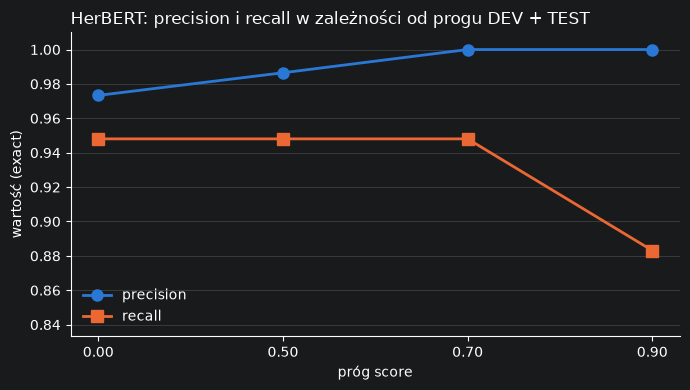

In [12]:
SERIES = (("precision", "#2a78d6", "o"), ("recall", "#eb6834", "s"))

x = range(len(threshold_df))
lo = threshold_df[[c for c, _, _ in SERIES]].min().min()

fig, ax = plt.subplots(figsize=(7, 4))
for col, color, marker in SERIES:
    ax.plot(x, threshold_df[col], marker=marker, markersize=8, linewidth=2, color=color, label=col)

ax.set_xticks(x, [f"{t:.2f}" for t in threshold_df.index])
ax.set_ylim(max(0.0, lo - 0.05), 1.01)
ax.set_xlabel("próg score")
ax.set_ylabel("wartość (exact)")
ax.set_title("HerBERT: precision i recall w zależności od progu DEV + TEST", loc="left")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
plt.show()

### Komentarz do wyników

Najlepszy kompromis daje próg **0.70**: F1 = 0.973 (najwyższe ze wszystkich progów), coverage = 0.973 (zostaje 73 z 75 predykcji), precision = 1.000 i recall = 0.948. Względem braku progu odrzucamy tylko 2 predykcje, a precision rośnie z 0.973 do 1.000 bez straty recallu. Próg 0.50 poprawia wynik niewiele (odrzuca 1 predykcję), a próg 0.90 jest już za wysoki: recall spada do 0.883, a F1 do 0.938, bo oprócz błędnych predykcji model traci też poprawne encje. Model jest bardzo pewny swoich predykcji, więc podniesienie progu poprawia precision tylko nieznacznie, a od pewnego momentu wyraźnie obniża recall.

# Zadanie 6: LLM i odpowiedź w formacie JSON

Proszę przygotować polecenie dla modelu językowego (prompt), które nakazuje zwrócić wyłącznie obiekt JSON z listą encji, np. `{"entities": [{"text": "...", "label": "PER"}]}`. Model musi obsługiwać język polski (patrz „Ustawienia wstępne”). Prompt (w tym ewentualne przykłady wzorcowe) tworzymy na części DEV; przykłady z TEST nie mogą trafić do promptu. Zalecane ustawienie: `temperature = 0`.

Należy:

1. zdefiniować oczekiwany schemat odpowiedzi;
2. uruchomić LLM na całym zbiorze TEST;
3. sprawdzić poprawność składni JSON;
4. sprawdzić zgodność ze schematem;
5. odzyskać `start`/`end` na podstawie literalnego tekstu encji; jeśli ten sam tekst występuje w dokumencie kilka razy, każde jego wystąpienie przypisujemy najwyżej jednej encji;
6. wykrywać encje, których nie można odnaleźć w tekście;
7. zmierzyć średni czas przetwarzania dokumentu.

Dla odpowiedzi z niepoprawnym JSON-em proszę zastosować maksymalnie jedno automatyczne ponowne wywołanie (`retry`) z informacją o błędzie formatu.

Proszę policzyć:

- JSON validity (odsetek odpowiedzi będących poprawnym JSON-em);
- schema validity (odsetek odpowiedzi zgodnych ze schematem);
- exact F1;
- relaxed F1;
- F1 osobno dla każdej klasy;
- liczbę encji niewystępujących w tekście;
- średni czas na dokument;
- liczbę dodatkowych wywołań spowodowanych przez `retry`.

**Uwaga.** Ollama pozwala wymusić format odpowiedzi parametrem `format` (można w nim podać schemat JSON). Podstawowa wersja zadania ma polegać na samym poleceniu w prompcie, **bez** tego parametru -- wtedy poprawność formatu jest wynikiem eksperymentu, a `retry` ma sens.

## Część opcjonalna

Proszę powtórzyć eksperyment z parametrem `format` ze schematem JSON i porównać z wersją podstawową: poprawność formatu, jakość (exact F1) i czas.

In [13]:
# Proszę zaimplementować wywołanie LLM,
# walidację struktury, odzyskiwanie zakresów i pojedynczy retry.

OLLAMA_URL = "http://localhost:11434/api/chat"
LLM_MODEL = "hf.co/speakleash/Bielik-4.5B-v3.0-Instruct-GGUF:Q8_0"

SYSTEM_PROMPT = """Jesteś systemem rozpoznawania nazw własnych w tekstach polskich.
Znajdź w tekście wszystkie encje trzech klas:
- PER: osoba (bez tytułu i stanowiska),
- ORG: organizacja, firma, instytucja,
- LOC: lokalizacja (miasto, kraj).
Zwróć WYŁĄCZNIE obiekt JSON, bez komentarza i bez znaczników markdown, w formacie:
{"entities": [{"text": "...", "label": "PER"}]}
Pole "text" musi być dokładnym fragmentem tekstu, w takiej formie, w jakiej występuje w zdaniu.
Jeśli nie ma encji, zwróć {"entities": []}."""

FEW_SHOT_DOCS = [DEV[0], DEV[3]]

def few_shot_messages(docs):
    msgs = []
    for d in docs:
        answer = {"entities": [{"text": e["text"], "label": e["label"]} for e in d["entities"]]}
        msgs += [{"role": "user", "content": d["text"]},
                 {"role": "assistant", "content": json.dumps(answer, ensure_ascii=False)}]
    return msgs

def call_llm(messages):
    r = requests.post(OLLAMA_URL, json={"model": LLM_MODEL, "messages": messages, "stream": False,
                                        "options": {"temperature": 0}}, timeout=120)
    r.raise_for_status()
    return r.json()["message"]["content"]


def schema_error(obj):
    if not isinstance(obj, dict) or not isinstance(obj.get("entities"), list):
        return 'brak listy "entities"'
    for e in obj["entities"]:
        if not (isinstance(e, dict) and isinstance(e.get("text"), str) and e.get("label") in LABELS):
            return f"zła encja: {e!r}"
    return None


def recover_spans(text, items):
    taken, found, missing = set(), [], 0
    for it in items:
        start = text.find(it["text"])
        while start != -1 and any(start < t_end and t_start < start + len(it["text"]) for t_start, t_end in taken):
            start = text.find(it["text"], start + 1)
        if start == -1 or not it["text"]:
            missing += 1
            continue
        end = start + len(it["text"])
        taken.add((start, end))
        found.append({"text": it["text"], "label": it["label"], "start": start, "end": end})
    return sorted(found, key=lambda e: e["start"]), missing


def llm_doc(doc):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, *few_shot_messages(FEW_SHOT_DOCS),
                {"role": "user", "content": doc["text"]}]
    stats = {"json_ok": False, "schema_ok": False, "retries": 0, "missing": 0}
    raw = call_llm(messages)
    for attempt in range(2):
        try:
            obj = json.loads(raw)
            stats["json_ok"] = stats["json_ok"] or attempt == 0
            break
        except json.JSONDecodeError as err:
            if attempt == 1:
                obj = None
                break
            stats["retries"] += 1
            messages += [{"role": "assistant", "content": raw},
                         {"role": "user", "content": f"To nie jest poprawny JSON ({err}). "
                                                     "Zwróć wyłącznie poprawny obiekt JSON w podanym formacie."}]
            raw = call_llm(messages)
    entities = []
    if obj is not None and schema_error(obj) is None:
        stats["schema_ok"] = True
        entities, stats["missing"] = recover_spans(doc["text"], obj["entities"])
    return {"doc_id": doc["doc_id"], "text": doc["text"], "entities": entities}, stats

In [15]:
import time
t = time.perf_counter()
llm_results = [llm_doc(d) for d in TEST]
llm_ms = (time.perf_counter() - t) / len(TEST) * 1000
llm_pred_test = [p for p, _ in llm_results]
llm_stats = [s for _, s in llm_results]

llm_row = {**report(TEST, "LLM", predict_fn=lambda docs: llm_pred_test), "ms/dok": llm_ms}
n = len(TEST)
llm_extra = {"JSON validity": sum(s["json_ok"] for s in llm_stats) / n,
             "schema validity": sum(s["schema_ok"] for s in llm_stats) / n,
             "encje spoza tekstu": sum(s["missing"] for s in llm_stats),
             "dodatkowe wywołania (retry)": sum(s["retries"] for s in llm_stats)}
display(pd.DataFrame([llm_row]).set_index("zbiór").round(3).T)
display(pd.Series(llm_extra))

zbiór,LLM
exact P,0.935
exact R,0.827
exact F1,0.878
relaxed P,0.978
relaxed R,0.865
relaxed F1,0.918
błędy granic,2.000
F1 PER,0.960
F1 ORG,0.900
F1 LOC,0.788


JSON validity                  1.0
schema validity                1.0
encje spoza tekstu             6.0
dodatkowe wywołania (retry)    0.0
dtype: float64

### Komentarz do wyników

**Schemat odpowiedzi.** Oczekiwany obiekt JSON: `{"entities": [{"text": "<fragment zdania>", "label": "PER" | "ORG" | "LOC"}]}`. Odpowiedź jest zgodna ze schematem, gdy ma listę `entities`, a każdy element ma pole `text` (napis) i `label` z dozwolonego zbioru. Funkcja `schema_error` sprawdza to w kodzie, a prompt zawiera ten sam opis i 2 przykłady z DEV.

**Wyniki na TEST.** JSON validity i schema validity wynoszą 1.0, a liczba dodatkowych wywołań (`retry`) 0. Model Bielik poradził sobie więc z formatem bez wymuszania go parametrem `format`. Oznacza to jednak, że **mechanizm `retry` nigdy się nie uruchomił** i nie został sprawdzony na prawdziwym błędzie. JSON validity liczymy po pierwszej odpowiedzi, a schema validity po odpowiedzi końcowej.

Jakość (exact F1 = 0.878, relaxed F1 = 0.918) jest niższa niż HerBERTa, a czas na dokument (ok. 2400 ms) wielokrotnie dłuższy. Różnica między exact i relaxed to 2 błędy granic.

**Encje spoza tekstu: 6.** Model zwracał `text` zmieniony względem zdania (np. „Jan Kowalski” zamiast „Jana Kowalskiego”, „Paryżu” zamiast „Paryża”, literówka w „Mimo Wszyssko”), więc zakresów nie dało się odzyskać dosłownie i te encje liczą się jako pominięcia. Dwa błędy granic to forma podstawowa będąca prefiksem formy odmienionej („Wrocław” zamiast „Wrocławiem”). Źródłem większości błędów LLM jest więc brak literalnego kopiowania tekstu, a nie błędne rozpoznanie encji.

# Zadanie 7: Porównanie trzech podejść

Proszę przygotować jedną tabelę:

| system | exact F1 | relaxed F1 | boundary errors | PER F1 | ORG F1 | LOC F1 | ms/dok | poprawność formatu |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| reguły | | | | | | | | 1.00 |
| pretrained NER | | | | | | | | 1.00 |
| LLM | | | | | | | | |
| (opcjonalnie) model NER (spaCy) | | | | | | | | 1.00|



Proszę dodatkowo wskazać:

- system z najwyższym exact F1;
- system z najwyższym recall;
- system najszybszy;
- system o najbardziej przewidywalnym typie błędów.

Nie należy wybierać „zwycięzcy” na podstawie jednej liczby ani bez sprawdzenia, czy różnica jest większa niż niepewność oszacowania — zbiór TEST ma tylko 20 dokumentów i 52 encje.

*(opcjonalne)* Proszę podać 95% przedział ufności dla exact F1 każdego systemu (bootstrap po dokumentach, jak w laboratorium 2).

In [21]:
# Proszę zebrać wyniki wszystkich systemów w jednej tabeli.

rules_pred = predict(TEST)
ner_pred = ner_predict(TEST)


SYSTEMS = {
    "reguły":  (rules_pred,    report(TEST, "reguły")["ms/dok"], 1.0),
    "HerBERT": (ner_pred,      report(TEST, "HerBERT", predict_fn=ner_predict)["ms/dok"], 1.0),
    "LLM":     (llm_pred_test, llm_ms, llm_extra["JSON validity"]),
}


def bootstrap_f1_ci(gold, pred, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    f1s = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(gold), size=len(gold))
        f1s.append(exact_span_metrics([gold[i] for i in idx], [pred[i] for i in idx])["f1"])
    return np.percentile(f1s, [2.5, 97.5])


rows = []
for name, (pred, ms, fmt) in SYSTEMS.items():
    ex, rx = exact_span_metrics(TEST, pred), relaxed_span_metrics(TEST, pred)
    lo, hi = bootstrap_f1_ci(TEST, pred)
    rows.append({"system": name,
                 "exact F1": ex["f1"], "95% CI": f"[{lo:.2f}, {hi:.2f}]",
                 "exact R": ex["recall"], "relaxed F1": rx["f1"],
                 "boundary errors": count_boundary_errors(TEST, pred),
                 **{f"{lab} F1": exact_span_metrics(only(TEST, lab), only(pred, lab))["f1"] for lab in ["PER", "ORG", "LOC"]},
                 "ms/dok": ms, "poprawność formatu": fmt})

final_df = pd.DataFrame(rows).set_index("system")
display(final_df)



print("najwyższy exact F1:", final_df["exact F1"].idxmax())
print("najwyższy recall:", final_df["exact R"].idxmax())
print("najszybszy:", final_df["ms/dok"].idxmin())



,exact F1,95% CI,exact R,relaxed F1,boundary errors,PER F1,ORG F1,LOC F1,ms/dok,poprawność formatu
system,,,,,,,,,,
reguły,0.659091,"[0.54, 0.78]",0.557692,0.659091,0,0.787879,0.428571,0.740741,0.089458,1.0
HerBERT,0.950495,"[0.90, 0.99]",0.923077,0.970297,1,1.000000,0.878049,1.000000,16.956129,1.0
LLM,0.877551,"[0.80, 0.94]",0.826923,0.918367,2,0.960000,0.900000,0.787879,2417.765533,1.0


najwyższy exact F1: HerBERT
najwyższy recall: HerBERT
najszybszy: reguły


### Wnioski z porównania (TEST)

| kryterium | system | wartość |
|---|---|---|
| najwyższy exact F1 | HerBERT | 0.950 (reguły 0.659, LLM 0.878) |
| najwyższy recall | HerBERT | 0.923 (reguły 0.558, LLM 0.827) |
| najszybszy | reguły | ok. 0.09 ms/dok (HerBERT ok. 17 ms, LLM ok. 2400 ms) |
| najbardziej przewidywalny typ błędów | reguły | 0 błędów granic, pomyłki tylko w dwóch typach: pominięcie nazwy spoza słownika i organizacja uznana za osobę |

**Czy różnice są większe niż niepewność?**

TEST ma 20 dokumentów i 52 encje, więc przedziały ufności (bootstrap po dokumentach, 95%) są szerokie: reguły [0.54, 0.78], HerBERT [0.90, 0.99], LLM [0.80, 0.94].
- Reguły są wyraźnie gorsze od obu pozostałych systemów (górna granica reguł 0.78 jest poniżej dolnej granicy LLM 0.80).
- **HerBERT i LLM nie dają się rozróżnić:** ich przedziały nachodzą na siebie (0.90–0.94), więc przewagi HerBERTa w exact F1 nie można uznać za pewną. Dlatego „najlepszy” oznacza tu najwyższą wartość punktową, a nie istotnie lepszy system.
- Różnica czasu (rzędy wielkości) jest natomiast pewna i nie zależy od rozmiaru zbioru.

**Przewidywalność błędów.** Błędy reguł da się przewidzieć z góry: system pominie każdą nazwę, której nie ma w słowniku, i uzna za osobę każdą nazwę dwuwyrazową bez słowa-wyzwalacza. HerBERT popełnia niewiele błędów (4), ale trudno przewidzieć, kiedy pominie encję. Błędy LLM mają wiele przyczyn (zmiana formy, literówki, błędna klasa), a wynik może się zmieniać z promptem.

**Poprawność formatu** wynosi 1.00 dla wszystkich systemów, ale dla LLM nie jest to oczywiste (JSON validity 1.0 zmierzone bez `retry`). Jednocześnie 6 encji LLM nie występowało w tekście, więc poprawny format nie oznacza poprawnej treści.

# Zadanie 8: Analiza błędów

Proszę przygotować wspólną tabelę dokładnie 12 błędnych przypadków ze zbioru TEST: po 4 z każdego z trzech systemów (reguły, HerBERT, LLM).

Proponowana taksonomia:

- `FP_SPURIOUS`: wykryto encję, której nie powinno być;
- `FN_MISSED`: pominięto encję;
- `BOUNDARY`: błędne granice;
- `LABEL`: błędna klasa;
- `NORMALIZATION`: problem normalizacji lub mapowania etykiety;
- `FORMAT`: niepoprawny format odpowiedzi LLM;
- `HALLUCINATION`: encja niewystępująca w tekście;
- `GOLD_ISSUE`: wątpliwa lub niespójna adnotacja w zbiorze referencyjnym
- `OTHER`: inny błąd.

Tabela:

| nr | system | doc_id | typ błędu | gold | predykcja | komentarz |
|---:|---|---:|---|---|---|---|

Proszę zadbać o to, aby tabela zawierała różne rodzaje błędów, a nie 12 wariantów tego samego problemu.


### Analiza błędów (TEST)

| nr | system | doc_id | typ błędu | gold | predykcja | komentarz |
|---:|---|---:|---|---|---|---|
| 1 | reguły | 8 | `FN_MISSED` | Google (ORG) | — | Jednowyrazowa nazwa firmy: nie ma jej w słowniku ORG, nie zawiera słowa-wyzwalacza, a reguła PER wymaga 2–3 słów. |
| 2 | reguły | 25 | `FN_MISSED` | Seulu (LOC) | — | Miasto spoza gazetteera. Słownik nie uogólnia na nowe nazwy (to samo dotyczy Londynu, Berlina, Paryża). |
| 3 | reguły | 22 | `LABEL` | TVP Sport (ORG) | TVP Sport (PER) | Dwa słowa z wielkiej litery to domyślnie PER. Bez słowa-wyzwalacza reguły nie odróżniają organizacji od osoby. |
| 4 | reguły | 29 | `LABEL` | OpenAI (ORG) | Zespół OpenAI (PER) | Rzeczownik pospolity „Zespół” (wielka litera na początku zdania) dokleja się do nazwy: złe granice i zła klasa naraz. |
| 5 | HerBERT | 8 | `FN_MISSED` | Google (ORG) | — | Model nie wykrył znanej firmy na początku zdania. To nie błąd formatu ani granic: encja po prostu nie została zwrócona. |
| 6 | HerBERT | 25 | `FN_MISSED` | Samsung (ORG) | — | Jak wyżej: jednowyrazowa nazwa firmy na początku zdania, bez wskazówki w kontekście. |
| 7 | HerBERT | 29 | `FN_MISSED` | OpenAI (ORG) | — | Nazwa wystąpiła po rzeczowniku „Zespół”; model nie uznał jej za organizację. |
| 8 | HerBERT | 14 | `BOUNDARY` | Mimo Wszystko (ORG) | Mimo (ORG) | Nazwa złożona ze zwykłych słów została ucięta po pierwszym słowie. To jedyny błąd granic HerBERTa na TEST. |
| 9 | LLM | 8 | `NORMALIZATION` | Jana Kowalskiego (PER) | Jan Kowalski (PER) | Model sprowadził nazwisko do mianownika, mimo polecenia o dokładnym fragmencie tekstu. Nie da się go odnaleźć w zdaniu, więc encja przepada. |
| 10 | LLM | 14 | `HALLUCINATION` | Mimo Wszystko (ORG) | fundacji Mimo Wszyssko (ORG) | Zwrócony napis nie występuje w tekście: dołączone słowo „fundacji” i literówka w nazwie. |
| 11 | LLM | 10 | `LABEL` | Uniwersytetu Jagiellońskiego (ORG) | Uniwersytetu Jagiellońskiego (LOC) | Zakres poprawny, ale model potraktował nazwę uczelni jako lokalizację. |
| 12 | LLM | 11 | `BOUNDARY` | Wrocławiem (LOC) | Wrocław (LOC) | Model podał formę podstawową, która jest prefiksem formy odmienionej. Odzyskiwanie zakresów znalazło ją jako podciąg, więc powstał błąd granic. |

HerBERT ma na TEST tylko 4 błędy i wszystkie są w tabeli, więc jego przypadki są mniej zróżnicowane niż u pozostałych systemów. Pozostałe dwa systemy mają błędy czterech różnych typów: reguły (`FN_MISSED`, `LABEL`), LLM (`NORMALIZATION`, `HALLUCINATION`, `LABEL`, `BOUNDARY`).

# Zadanie 9: Interpretacja wyników

To zadanie nie wymaga nowej implementacji.

Na podstawie wyników proszę odpowiedzieć:

1. Dlaczego exact F1 i relaxed F1 mogą prowadzić do różnych ocen tego samego systemu?
2. W którym zastosowaniu błąd granic jest szczególnie poważny i dlaczego?
3. Jakie typy błędów dominują w systemie regułowym, modelu NER i LLM?
4. Czy wysoki próg modelu NER zawsze poprawia cały system? Proszę uzasadnić odpowiedź wynikami zadania 5.
5. Które ograniczenie obecnego zbioru referencyjnego najbardziej utrudnia wyciąganie ogólnych wniosków? (Proszę uwzględnić m.in. liczebność zbioru, dobór zdań oraz to, że modele mogły widzieć podobne nazwy podczas uczenia.)
6. Jak fleksja języka polskiego wpływa na działanie systemu regułowego ze słownikiem w porównaniu z modelem NER?

**1. Dlaczego exact F1 i relaxed F1 mogą dawać różne oceny?**
Exact wymaga zgodności `start`, `end` i klasy. Relaxed uznaje trafienie, gdy zakresy się przecinają i klasa jest ta sama. Różnica pojawia się więc wtedy, gdy system znalazł właściwą encję, ale ze zbyt szerokim lub zbyt wąskim zakresem. Widać to w wynikach: reguły mają 0 błędów granic i identyczne F1 (0.659 i 0.659). HerBERT ma 1 błąd granic (F1 0.950 i 0.970), a LLM 2 (F1 0.878 i 0.918). Relaxed nie wybacza złej klasy, więc nie ukrywa błędów typu `LABEL`.

**2. W którym zastosowaniu błąd granic jest szczególnie poważny?**
Przede wszystkim w anonimizacji danych osobowych. Jeśli system zamaskuje tylko część nazwy, np. „Mimo” zamiast „Mimo Wszystko” albo samo imię bez nazwiska, w tekście zostaje fragment, który nadal identyfikuje osobę lub instytucję. Granice mają też znaczenie przy łączeniu encji z bazą wiedzy: ucięta nazwa „Mimo” wskaże zupełnie inny obiekt niż „Mimo Wszystko”. Metryka relaxed taki błąd wybacza, więc w tych zastosowaniach trzeba patrzeć na exact.

**3. Jakie typy błędów dominują?**
- **Reguły:** 16 pominięć (`FN_MISSED`) i 7 błędów klasy (`LABEL`), brak błędów granic. Pominięcia to jednowyrazowe organizacje (Google, Samsung) i miasta spoza słownika (Seul). Błędy klasy to organizacje dwuwyrazowe uznane za osoby („TVP Sport”).
- **HerBERT:** 3 pominięcia i 1 błąd granic („Mimo” zamiast „Mimo Wszystko”). Dominuje `FN_MISSED`: model pomija nazwy firm bez dodatkowego kontekstu (Google, Samsung, OpenAI).
- **LLM:** 6 pominięć, 2 błędy granic i 1 błąd klasy. Formalnie dominuje `FN_MISSED`, ale jego przyczyna jest jedna: model nie kopiuje tekstu literalnie. Wszystkie 6 pominięć to encje spoza tekstu, np. ze zmienioną formą odmiany albo literówką, więc nie dało się odzyskać ich zakresów. Oba błędy granic mają to samo źródło („Wrocław” zamiast „Wrocławiem”).

**4. Czy wysoki próg modelu NER zawsze poprawia cały system?**
Nie. Bez progu HerBERT ma precision 0.973, recall 0.948, F1 0.961. Próg 0.70 odrzuca dokładnie 2 błędne predykcje, więc precision rośnie do 1.000, recall się nie zmienia, a F1 rośnie do 0.973 (najlepszy wynik). Próg 0.90 nie poprawia już precision (nadal 1.000), ale odrzuca 5 poprawnych encji: recall spada do 0.883, F1 do 0.938, a coverage do 0.907. Dalsze podnoszenie progu tylko traci poprawne wyniki. Optymalny próg zależy od kosztu błędów: tam, gdzie pominięcie encji jest drogie (np. anonimizacja), próg powinien być niski. Wynik jest też liczony na DEV + TEST razem, więc wybór progu jest lekko optymistyczny.

**5. Które ograniczenie zbioru referencyjnego najbardziej utrudnia wyciąganie wniosków?**
Liczebność. TEST ma 20 dokumentów i 52 encje, więc przedziały ufności są szerokie: reguły [0.54, 0.78], HerBERT [0.90, 0.99], LLM [0.80, 0.94]. Przedziały HerBERTa i LLM nachodzą na siebie, więc nie można stwierdzić, który z nich jest lepszy. Drugie ograniczenie to dobór zdań: krótkie, jednozdaniowe, o znanych osobach i instytucjach, w typowych konstrukcjach. Nie ma tekstów prasowych ani urzędowych. Do tego HerBERT uczył się na Wikipedii, a LLM mógł widzieć te same nazwy, więc ich wyniki mogą być zawyżone. Reguły i słownik powstały pod tę samą dziedzinę, a spadek z DEV na TEST (1.000 do 0.659) pokazuje, jak słabo uogólniają.

**6. Jak fleksja wpływa na reguły ze słownikiem w porównaniu z modelem NER?**
Słownik zna tylko to, co mu wpisano. Formy odmienione obsługujemy rdzeniem i listą końcówek, a każda oboczność wymaga osobnego wpisu (Kraków/Krakow, Łódź/Łodzi, Praga/Pradze). Nazwy odmieniane jak przymiotniki (Białystok → Białymstoku) w ogóle nie pasują, a każda nowa nazwa wymaga ręcznego dopisania. HerBERT dzieli słowa na podsłowa i patrzy na kontekst, więc rozpoznaje różne formy tej samej nazwy bez listy końcówek. Na TEST ma LOC F1 = 1.0, a reguły 0.741. U reguł główną przyczyną nie jest jednak sama odmiana (odmienione formy ze słownika działały), tylko brak miast w słowniku. Fleksja szkodzi też LLM, ale inaczej: model zamienia odmienioną formę na mianownik („Jan Kowalski”, „Paryż”), przez co tekstu nie da się znaleźć w zdaniu, a encja przepada.

# Zadanie 10: Decyzja projektowa

To zadanie nie wymaga nowej implementacji.

Proszę wybrać rozwiązanie dla trzech scenariuszy:

1. anonimizacja danych osobowych, gdzie pominięcie encji jest bardzo kosztowne;
2. szybkie oznaczanie znanych organizacji i lokalizacji w dużym strumieniu tekstu;
3. system, w którym schemat encji może często się zmieniać.

Dla każdego scenariusza proszę podać:

- wybrane podejście;
- jedną metrykę uzasadniającą wybór;
- dominujący typ błędu;
- najważniejszy koszt lub ograniczenie.

Na końcu proszę odpowiedzieć jednym akapitem:

**Dlaczego model o najwyższym F1 nie musi być najlepszym systemem ekstrakcji informacji?**


**1. Anonimizacja danych osobowych (pominięcie encji jest bardzo kosztowne)**
- **Podejście:** HerBERT, bez progu pewności.
- **Metryka:** recall. Pominięta osoba to wyciek danych, a nadmiarowa maska kosztuje mało. HerBERT ma najwyższy recall na TEST (0.923, reguły 0.558, LLM 0.827), a dla klasy PER exact F1 = 1.0, czyli żadna osoba nie została pominięta. Ma też tylko 1 błąd granic, co jest ważne, bo ucięta nazwa zostawia fragment identyfikujący osobę.
- **Dominujący błąd:** `FN_MISSED`. Model pomija jednowyrazowe nazwy firm (Google, Samsung, OpenAI), ale nie osoby.
- **Koszt i ograniczenie:** model wymaga pobrania ok. 0,5 GB i działa wolniej niż reguły (ok. 17 ms na dokument). Uczył się na Wikipedii, więc na tekstach z innej dziedziny recall może być niższy. Próg wyższy niż 0.70 obniża recall (przy 0.90 spada do 0.883), więc stosujemy go tu najwyżej ostrożnie. Wynik PER opiera się tylko na 13 encjach, więc nie jest gwarancją.

**2. Szybkie oznaczanie znanych organizacji i lokalizacji w dużym strumieniu tekstu**
- **Podejście:** reguły ze słownikiem (gazetteer) i odmianą.
- **Metryka:** czas na dokument: 0.09 ms, czyli ok. 190 razy szybciej niż HerBERT (17 ms) i ok. 27 000 razy szybciej niż LLM (ok. 2400 ms). Słownik jest pełny dla znanych nazw, a nowych nazw i tak nie szukamy.
- **Dominujący błąd:** `FN_MISSED` dla nazw spoza słownika (16 pominięć na TEST). Reguła PER bywa też źródłem błędów klasy (`LABEL`), więc w tym scenariuszu warto ją wyłączyć.
- **Koszt i ograniczenie:** słownik trzeba ręcznie utrzymywać razem z formami odmienionymi (rdzenie, oboczności, nazwy odmieniane jak przymiotniki). System nie uogólnia na nowe nazwy.

**3. Schemat encji często się zmienia**
- **Podejście:** LLM z odpowiedzią w formacie JSON.
- **Metryka:** schema validity i JSON validity = 1.0 (po pierwszej odpowiedzi, bez retry), przy exact F1 = 0.878 bez dostrajania. Nowy schemat to zmiana promptu, a nie nowe dane do trenowania HerBERTa ani nowe reguły.
- **Dominujący błąd:** `FN_MISSED` spowodowane tym, że model nie kopiuje tekstu literalnie. 6 encji było spoza tekstu (zmieniona forma odmiany, literówka), a 2 błędy granic mają to samo źródło.
- **Koszt i ograniczenie:** ok. 2400 ms na dokument (ok. 140 razy wolniej niż HerBERT) i potrzebna infrastruktura (Ollama, 5 GB). Wyniki zależą od promptu. Jakość sprawdziliśmy tylko dla PER/ORG/LOC, więc dla nowych klas trzeba ją zmierzyć od nowa.

**Dlaczego model o najwyższym F1 nie musi być najlepszym systemem ekstrakcji informacji?**
F1 to jedna liczba, która uśrednia precision i recall, a w zastosowaniach błędy mają różny koszt: przy anonimizacji liczy się recall, przy oznaczaniu znanych nazw w dużym strumieniu przede wszystkim czas. Dlatego najlepszy w wyborze bywa system słabszy w F1, ale ok. 190 razy szybszy (reguły względem HerBERTa), jeśli przetwarzamy duże ilości tekstu. Liczą się też typ błędów (pominięcie, zły zakres, zła klasa), koszt utrzymania (słownik, trenowanie, prompt), infrastruktura i to, czy wynik jest przewidywalny. Do tego dochodzi niepewność: TEST ma tylko 52 encje, a przedziały ufności HerBERTa [0.90, 0.99] i LLM [0.80, 0.94] nachodzą na siebie, więc różnica w F1 może wynikać z doboru zdań. O wyborze decyduje więc zastosowanie, a nie jedna liczba.

# Karta systemu

Proszę wybrać rozwiązanie rekomendowane do jednego konkretnego zastosowania i utworzyć:

```text
artifacts/information_extraction_model_card.md
```

Karta powinna zawierać:

## System
- wybrane podejście: reguły / NER / LLM;
- nazwa modelu, źródło (np. Hugging Face lub Ollama), kwantyzacja lub wersja, licencja -- jeśli dotyczy;
- format zwracanych encji.

## Zadanie
- rozpoznawane klasy;
- wytyczne anotacji;
- konwencja zakresów.

## Dane
- liczba dokumentów i encji (osobno DEV i TEST);
- rozkład klas.

## Ewaluacja (na TEST)
- exact precision / recall / F1;
- relaxed precision / recall / F1;
- F1 per klasa;
- błędy granic.

## Koszt
- średni czas na dokument;
- dodatkowe wymagania modelowe lub infrastrukturalne.

## Błędy
- dominujące typy błędów z analizy 12 przypadków.

## Zastosowanie
- do czego system jest rekomendowany;
- kiedy należy wybrać inne podejście.

## Ograniczenia
- ograniczenia zbioru (m.in. liczebność, dobór zdań);
- ograniczenia metryk;
- ograniczenia samego systemu.

# Warunki zaliczenia laboratorium

Laboratorium jest ukończone, jeśli zawiera:

- [ ] audyt zbioru referencyjnego i podział na DEV / TEST;
- [ ] własną implementację exact precision / recall / F1;
- [ ] własną implementację relaxed precision / recall / F1;
- [ ] wykrywanie błędów granic;
- [ ] system regułowy ze słownikiem nazw (`gazetteer`) i obsługą fleksji;
- [ ] model NER dla języka polskiego (HerBERT);
- [ ] eksperyment z progami `0.00`, `0.50`, `0.70`, `0.90`;
- [ ] LLM (z obsługą języka polskiego) zwracający odpowiedź w formacie JSON;
- [ ] JSON validity i schema validity;
- [ ] odzyskiwanie `start/end`;
- [ ] maksymalnie jeden `retry` dla błędu formatu;
- [ ] wspólną tabelę porównawczą trzech podejść;
- [ ] tabelę 12 błędnych przypadków (po 4 z każdego systemu);
- [ ] odpowiedzi do zadań interpretacyjnych (9 i 10);
- [ ] plik `artifacts/information_extraction_model_card.md`.